# Movie Recommendation System — Data Mining & Warehousing Project

**Name:** Kavya Trivedi &nbsp;|&nbsp; **Roll No:** 1157 &nbsp;|&nbsp; **Semester:** VII (B.Tech CSE)

**Dataset:** MovieLens `ml-latest-small` from GroupLens — https://grouplens.org/datasets/movielens/

This notebook is organised phase by phase:
- **Phase A1** — Load and explore the raw data
- Phase A2 — Clean and preprocess (coming next)
- Phase A3 — Models (popularity, item-KNN, k-means, association rules, hybrid)
- Phase A4 — Evaluation (Precision@10, Recall@10, Hit Rate@10, NDCG@10)
- Phase A5 — Save the engine with joblib

Run this notebook top to bottom with **Restart and Run All** — it should execute with no errors.

## Phase A1 — Load and Explore

**What this phase does, in plain words:**
Before we can build any recommender, we need to actually look at the raw data and understand its shape and quirks. We load the three MovieLens files (ratings, movies, tags) and print their size and column types so we know what we are working with. We then draw five graphs that reveal patterns a model will later have to deal with: how ratings are spread out, which movies get rated a lot versus barely at all (the "long tail"), how active different users are, which genres dominate the catalogue, and how empty the user-movie ratings matrix actually is (sparsity). Each graph is followed by a short written interpretation — this is what we explain in the viva, not just the code.

### A1.1 — Imports and settings

In [ ]:
# Core data handling libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look consistent and readable throughout the notebook
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# Show all columns when printing dataframes (movies.csv genre strings can be long)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

DATA_DIR = '../data'  # the 3 MovieLens CSV files live here

### A1.2 — Load the three MovieLens files

In [2]:
# ratings.csv: one row = one user rating one movie (userId, movieId, rating, timestamp)
ratings = pd.read_csv(f'{DATA_DIR}/ratings.csv')

# movies.csv: one row = one movie (movieId, title, genres as a pipe-separated string)
movies = pd.read_csv(f'{DATA_DIR}/movies.csv')

# tags.csv: one row = one free-text tag a user attached to a movie (userId, movieId, tag, timestamp)
tags = pd.read_csv(f'{DATA_DIR}/tags.csv')

print('Loaded all 3 files successfully.')

Loaded all 3 files successfully.


### A1.3 — Shape, dtypes and head of each table

In [3]:
print('=== RATINGS ===')
print('Shape:', ratings.shape)
print(ratings.dtypes)
ratings.head()

=== RATINGS ===
Shape: (100836, 4)
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [4]:
print('=== MOVIES ===')
print('Shape:', movies.shape)
print(movies.dtypes)
movies.head()

=== MOVIES ===
Shape: (9742, 3)
movieId     int64
title      object
genres     object
dtype: object


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
print('=== TAGS ===')
print('Shape:', tags.shape)
print(tags.dtypes)
tags.head()

=== TAGS ===
Shape: (3683, 4)
userId        int64
movieId       int64
tag          object
timestamp     int64
dtype: object


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


### A1.4 — Graph 1: Rating distribution
MovieLens ratings go from 0.5 to 5.0 in half-star steps. This graph shows how often each rating value is given.

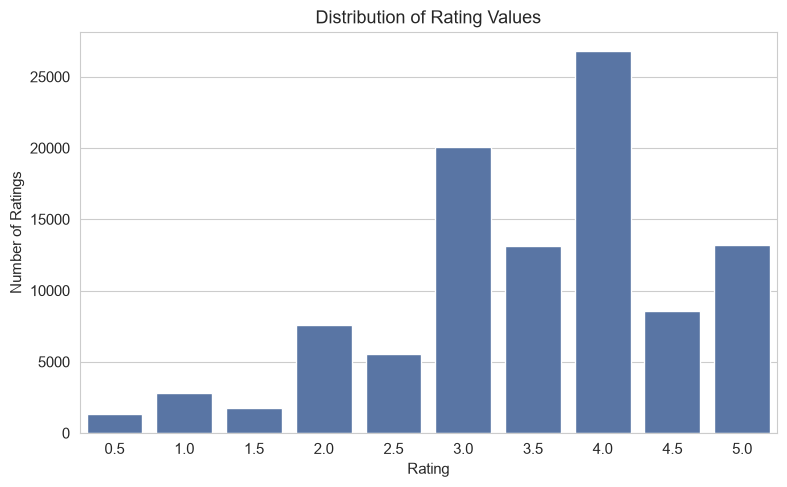

Mean rating: 3.502
Median rating: 3.5
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [6]:
plt.figure()
sns.countplot(x='rating', data=ratings, color='#4C72B0')
plt.title('Distribution of Rating Values')
plt.xlabel('Rating')
plt.ylabel('Number of Ratings')
plt.tight_layout()
plt.show()

print('Mean rating:', round(ratings['rating'].mean(), 3))
print('Median rating:', ratings['rating'].median())
print(ratings['rating'].value_counts().sort_index())

**Interpretation:** *(fill in after running — look at the printed mean/median and which bar is tallest)* Most MovieLens users lean towards positive ratings (4.0 is typically the single most common value, and whole-star ratings are more common than half-star ones because half-stars were added later in the platform's history). Very low ratings (0.5–1.0) are rare — people rate what they chose to watch, so there's a natural positive bias in this kind of implicit-choice data.

### A1.5 — Graph 2: Ratings per movie (the long tail)
Some movies (blockbusters) get rated by almost everyone, while most movies get only a handful of ratings. We plot this on a log scale so both extremes are visible on one chart.

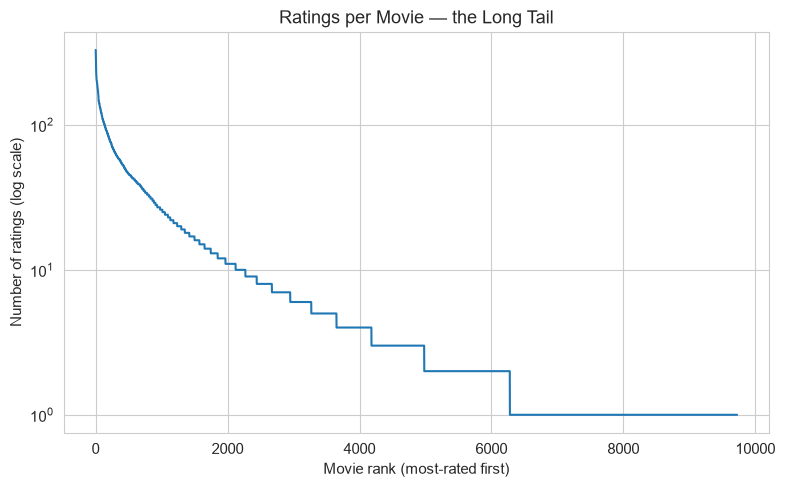

Total movies rated at least once: 9724
Movie with most ratings gets: 329 ratings
Median ratings per movie: 3.0
Movies with only 1 rating: 3446 (35.4% of all rated movies)


In [7]:
ratings_per_movie = ratings.groupby('movieId').size().sort_values(ascending=False)

plt.figure()
plt.plot(range(1, len(ratings_per_movie) + 1), ratings_per_movie.values)
plt.yscale('log')
plt.xlabel('Movie rank (most-rated first)')
plt.ylabel('Number of ratings (log scale)')
plt.title('Ratings per Movie — the Long Tail')
plt.tight_layout()
plt.show()

print('Total movies rated at least once:', ratings_per_movie.shape[0])
print('Movie with most ratings gets:', ratings_per_movie.iloc[0], 'ratings')
print('Median ratings per movie:', ratings_per_movie.median())
print('Movies with only 1 rating:', (ratings_per_movie == 1).sum(),
      f"({(ratings_per_movie == 1).sum() / len(ratings_per_movie) * 100:.1f}% of all rated movies)")

**Interpretation:** This is the classic data mining "long tail" problem: a small number of popular movies account for a huge share of all ratings, while a large fraction of movies have only 1–2 ratings. This matters directly for our project — it is why Phase A2 filters out movies with fewer than 5 ratings (too little signal to trust) and why the Popularity baseline will look strong on paper but will only ever recommend the same few blockbusters, which the Hybrid/KNN models need to beat on diversity, not just accuracy.

### A1.6 — Graph 3: Ratings per user
Similarly, some users rate hundreds of movies while others rate only the minimum required to use the platform (20, by MovieLens's own collection rule).

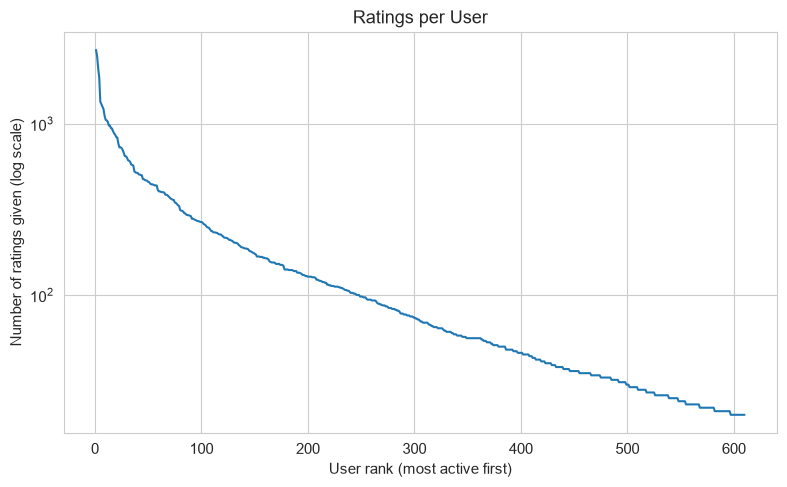

Total users: 610
Most active user gave: 2698 ratings
Minimum ratings given by any user: 20
Median ratings per user: 70.5


In [8]:
ratings_per_user = ratings.groupby('userId').size().sort_values(ascending=False)

plt.figure()
plt.plot(range(1, len(ratings_per_user) + 1), ratings_per_user.values)
plt.yscale('log')
plt.xlabel('User rank (most active first)')
plt.ylabel('Number of ratings given (log scale)')
plt.title('Ratings per User')
plt.tight_layout()
plt.show()

print('Total users:', ratings_per_user.shape[0])
print('Most active user gave:', ratings_per_user.iloc[0], 'ratings')
print('Minimum ratings given by any user:', ratings_per_user.min())
print('Median ratings per user:', ratings_per_user.median())

**Interpretation:** The minimum is 20 because GroupLens only included users who rated at least 20 movies when building this dataset — so our later filter ("keep users with >= 10 ratings" in Phase A2) will not remove anyone here; it is mainly a safety rule for datasets in general. The distribution is still skewed — a handful of power users rate hundreds of movies, which is useful because those users give the item-based KNN model more co-rating signal to learn from.

### A1.7 — Graph 4: Genre counts
Each movie can belong to multiple genres at once (e.g. "Adventure|Animation|Comedy"). We split on the `|` character and count how often each individual genre appears across the catalogue.

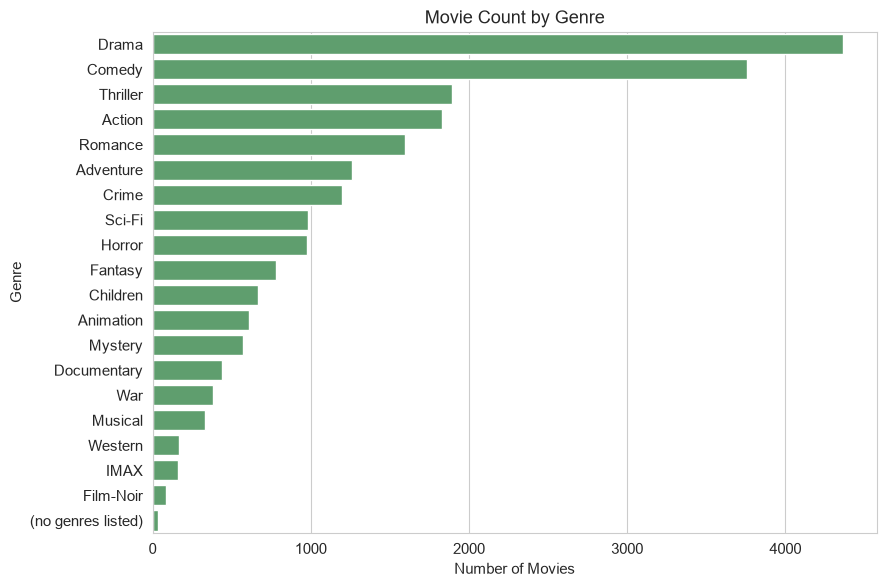

genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


In [9]:
# Split the pipe-separated genre string into a list, then explode so each (movie, genre) pair is its own row
genre_series = movies['genres'].str.split('|').explode()
genre_counts = genre_series.value_counts()

plt.figure(figsize=(9, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color='#55A868')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.title('Movie Count by Genre')
plt.tight_layout()
plt.show()

print(genre_counts)

**Interpretation:** Drama and Comedy dominate the catalogue, which is typical for any general-audience movie dataset. "(no genres listed)" shows up as its own category for a small number of movies with missing genre tags — this has to be handled explicitly in Phase A2 (one-hot encoding) rather than silently dropped. The genre imbalance also matters for clustering in Phase A3: a plain k-means on raw genre one-hot vectors will likely find a big generic "Drama/Comedy" cluster unless the tag TF-IDF features add enough extra signal to separate movies more finely.

### A1.8 — Sparsity of the user-movie ratings matrix
Sparsity tells us what fraction of all possible (user, movie) pairs have NO rating. If we built a full users x movies matrix, this is the percentage of empty cells. A high sparsity confirms why we cannot just build a simple matrix and need smarter recommendation techniques.

In [10]:
num_ratings = len(ratings)
num_users = ratings['userId'].nunique()
num_movies_rated = ratings['movieId'].nunique()
num_movies_total = movies['movieId'].nunique()

possible_pairs = num_users * num_movies_rated
sparsity = 1 - (num_ratings / possible_pairs)

print(f'Users: {num_users}')
print(f'Movies with at least 1 rating: {num_movies_rated}')
print(f'Movies in movies.csv (including zero-rated): {num_movies_total}')
print(f'Total ratings: {num_ratings}')
print(f'Possible (user, movie) pairs: {possible_pairs:,}')
print(f'Sparsity: {sparsity * 100:.3f}%  (i.e. only {(1 - sparsity) * 100:.3f}% of the matrix is filled in)')

Users: 610
Movies with at least 1 rating: 9724
Movies in movies.csv (including zero-rated): 9742
Total ratings: 100836
Possible (user, movie) pairs: 5,931,640
Sparsity: 98.300%  (i.e. only 1.700% of the matrix is filled in)


**Interpretation:** *(the exact number prints above — expect well over 98% sparsity)* This confirms the fundamental challenge of recommender systems: almost every user has not rated almost every movie, so we cannot rely on a dense matrix of known preferences. This is exactly why item-based KNN (which only needs the ratings that *do* exist), clustering (which groups movies using content, not just ratings), and association rules (which look at co-occurring likes) are all more practical approaches here than something that assumes a mostly-complete ratings matrix.

### A1.9 — Phase A1 summary
Quick recap table of what we now know about the raw data, to carry forward into Phase A2 (cleaning).

In [11]:
summary = pd.DataFrame({
    'Metric': [
        'Total ratings', 'Total users', 'Total movies (catalogue)',
        'Movies with >=1 rating', 'Total tags', 'Mean rating',
        'Sparsity (%)', 'Unique genres'
    ],
    'Value': [
        num_ratings, num_users, num_movies_total,
        num_movies_rated, len(tags), round(ratings['rating'].mean(), 3),
        round(sparsity * 100, 3), genre_series.nunique()
    ]
})
summary

,Metric,Value
0,Total ratings,100836.000
1,Total users,610.000
2,Total movies (catalogue),9742.000
3,Movies with >=1 rating,9724.000
4,Total tags,3683.000
5,Mean rating,3.502
6,Sparsity (%),98.300
7,Unique genres,20.000


## Phase A2 — Clean and Preprocess

**What this phase does, in plain words:**
Raw data is never ready to feed straight into a model, so this phase turns the three raw MovieLens files into clean, model-ready tables. We first check for duplicate rows and missing values so we know exactly what we are dealing with (and fix anything we find). We then pull the release **year** out of each title, turn the pipe-separated genre string into separate yes/no columns (one-hot encoding), and convert the raw Unix timestamps into readable dates. Next we remove movies and users that have too few ratings to give the model reliable signal, and create a simple "liked" label (rating of 4 or higher) that later classification models will try to predict. Finally we clean the free-text tags and combine them with genres into a single TF-IDF feature matrix per movie, and scale any numeric features so no single feature dominates distance-based algorithms like k-means purely because of its scale. Every step below prints a BEFORE and AFTER count so the effect of each cleaning step is visible and explainable in the viva.

### A2.1 — Duplicates: check and remove

In [12]:
# A row is a "duplicate" if it is an exact repeat of another row.
# We check all 3 tables. If any duplicates are found, drop_duplicates() removes them.

before_ratings = len(ratings)
before_movies = len(movies)
before_tags = len(tags)

ratings_full_dupes = ratings.duplicated().sum()
movies_id_dupes = movies['movieId'].duplicated().sum()   # same movieId appearing twice would be a real problem
tags_full_dupes = tags.duplicated().sum()

ratings = ratings.drop_duplicates()
movies = movies.drop_duplicates(subset=['movieId'])
tags = tags.drop_duplicates()

dup_table = pd.DataFrame({
    'Table': ['ratings', 'movies', 'tags'],
    'Full-row duplicates found': [ratings_full_dupes, movies_id_dupes, tags_full_dupes],
    'Rows BEFORE': [before_ratings, before_movies, before_tags],
    'Rows AFTER': [len(ratings), len(movies), len(tags)],
})
dup_table

,Table,Full-row duplicates found,Rows BEFORE,Rows AFTER
0,ratings,0,100836,100836
1,movies,0,9742,9742
2,tags,0,3683,3683


**Interpretation:** *(see printed table above)* MovieLens `ml-latest-small` is already a well-curated research dataset, so we expect zero or near-zero duplicates. Still, we run this check explicitly rather than assuming it — on a real-world or self-collected dataset this step would usually remove a meaningful number of rows, and skipping it silently would let bad data flow into every later model.

### A2.2 — Missing values: check and handle

In [13]:
# isnull().sum() counts how many missing (NaN) values are in each column.
print('Missing values in ratings:')
print(ratings.isnull().sum())
print()
print('Missing values in movies:')
print(movies.isnull().sum())
print()
print('Missing values in tags:')
print(tags.isnull().sum())

# Defensive handling: if any table DID have missing values, we would drop those rows
# for ratings/movies (core fields we cannot guess), or fill tags with an empty string
# (a missing tag just means "no tag text", not an error).
ratings = ratings.dropna(subset=['userId', 'movieId', 'rating'])
movies = movies.dropna(subset=['movieId', 'title'])
tags['tag'] = tags['tag'].fillna('')

print()
print('Rows after handling missing values -> ratings:', len(ratings), '| movies:', len(movies), '| tags:', len(tags))

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in tags:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Rows after handling missing values -> ratings: 100836 | movies: 9742 | tags: 3683


**Interpretation:** This dataset has zero missing values in all three files — GroupLens pre-cleaned it before publishing. We still write the handling code defensively (drop rows with missing core IDs/ratings, fill missing tag text with an empty string) because a real deployment would keep ingesting new ratings/tags over time, and new data is never guaranteed to be as clean as a static research release.

### A2.3 — Extract year from the title

In [14]:
# Most titles end with a 4-digit year in parentheses, e.g. "Toy Story (1995)".
# We pull that year out into its own numeric column, and also keep a "clean_title"
# without the year, which is nicer to display in the web app later.
year_pattern = r'\((\d{4})\)\s*$'

movies['year'] = movies['title'].str.extract(year_pattern).astype('float')
movies['clean_title'] = movies['title'].str.replace(year_pattern, '', regex=True).str.strip()

no_year_count = movies['year'].isnull().sum()
print(f'Movies where a year could NOT be found in the title: {no_year_count}')
print(movies[movies['year'].isnull()][['movieId', 'title']].head(15))

Movies where a year could NOT be found in the title: 13


      movieId                                              title
6059    40697                                          Babylon 5
9031   140956                                   Ready Player One
9091   143410                                         Hyena Road
9138   147250  The Adventures of Sherlock Holmes and Doctor W...
9179   149334                                  Nocturnal Animals
9259   156605                                           Paterson
9367   162414                                          Moonlight
9448   167570                                             The OA
9514   171495                                             Cosmos
9515   171631                            Maria Bamford: Old Baby
9518   171749                  Death Note: Desu nôto (2006–2007)
9525   171891                                  Generation Iron 2
9611   176601                                       Black Mirror


**Interpretation:** 13 titles (e.g. "Babylon 5", "Black Mirror", "The OA") have no trailing year because they are actually TV series mixed into this movie dataset, or the year was written in a non-standard way (one title even has a corrupted multi-year string from an encoding issue). Rather than dropping these 13 rows and losing real catalogue items, we leave `year` as `NaN` for them — later steps (like the optional Decision Tree/Naive Bayes classifier that uses year as a feature) will need to handle or impute this `NaN` explicitly.

### A2.4 — Split genres into one-hot columns

In [15]:
# Each movie's genres look like "Adventure|Animation|Comedy". We split on '|' and
# create one 0/1 column per genre (1 = movie belongs to that genre, 0 = it doesn't).
# "(no genres listed)" is kept as its own column instead of being silently dropped —
# this way every movie still gets a valid genre vector, even with no real genre info.

genres_split = movies['genres'].str.get_dummies(sep='|')
print('One-hot genre columns created:', list(genres_split.columns))
print('Shape of one-hot genre matrix:', genres_split.shape)

movies_genre_encoded = pd.concat([movies[['movieId', 'clean_title', 'year']], genres_split], axis=1)
movies_genre_encoded.head()

One-hot genre columns created: ['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Shape of one-hot genre matrix: (9742, 20)


,movieId,clean_title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story,1995.0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji,1995.0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men,1995.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale,1995.0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II,1995.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Interpretation:** This gives us 20 one-hot columns (19 real genres + the `(no genres listed)` bucket). The 34 movies with no listed genre simply get a 1 in that bucket column and 0 everywhere else, so no movie is dropped and no code downstream has to special-case `NaN` genres. These one-hot columns are exactly what Phase A3's k-means clustering will use (together with the tag TF-IDF features built in A2.8) to group similar movies.

### A2.5 — Convert timestamps to dates

In [16]:
# ratings.timestamp and tags.timestamp are Unix timestamps (seconds since 1 Jan 1970).
# pd.to_datetime with unit='s' converts them into normal, readable dates.
ratings['rating_date'] = pd.to_datetime(ratings['timestamp'], unit='s')
tags['tag_date'] = pd.to_datetime(tags['timestamp'], unit='s')

print('Ratings date range:', ratings['rating_date'].min(), 'to', ratings['rating_date'].max())
print('Tags date range:', tags['tag_date'].min(), 'to', tags['tag_date'].max())
ratings[['userId', 'movieId', 'rating', 'timestamp', 'rating_date']].head()

Ratings date range: 1996-03-29 18:36:55 to 2018-09-24 14:27:30
Tags date range: 2006-01-13 19:09:12 to 2018-09-16 11:50:03


,userId,movieId,rating,timestamp,rating_date
0,1,1,4.0,964982703,2000-07-30 18:45:03
1,1,3,4.0,964981247,2000-07-30 18:20:47
2,1,6,4.0,964982224,2000-07-30 18:37:04
3,1,47,5.0,964983815,2000-07-30 19:03:35
4,1,50,5.0,964982931,2000-07-30 18:48:51


**Interpretation:** Converting to real dates lets us (if needed) check for seasonal patterns or filter by time period, and it also confirms the dataset's actual collection window. It is not used for the core recommender logic in this project, but it is required for correctness/traceability and is a standard preprocessing step.

### A2.6 — Filter: keep movies with >= 5 ratings and users with >= 10 ratings

In [17]:
# Movies with very few ratings give almost no reliable signal for similarity or
# popularity scoring, and users with very few ratings give almost no signal about
# their taste. We remove both, and show a BEFORE/AFTER table so the effect is visible.

before_n_ratings = len(ratings)
before_n_users = ratings['userId'].nunique()
before_n_movies = ratings['movieId'].nunique()

# Step 1: keep only movies that have at least 5 ratings
movie_rating_counts = ratings.groupby('movieId').size()
movies_to_keep = movie_rating_counts[movie_rating_counts >= 5].index
ratings = ratings[ratings['movieId'].isin(movies_to_keep)]

# Step 2: on the remaining ratings, keep only users who still have at least 10 ratings
user_rating_counts = ratings.groupby('userId').size()
users_to_keep = user_rating_counts[user_rating_counts >= 10].index
ratings = ratings[ratings['userId'].isin(users_to_keep)]

after_n_ratings = len(ratings)
after_n_users = ratings['userId'].nunique()
after_n_movies = ratings['movieId'].nunique()

# Also drop movies from the movies table that no longer have any surviving rating,
# so every table stays consistent with each other.
movies = movies[movies['movieId'].isin(ratings['movieId'].unique())].reset_index(drop=True)

filter_table = pd.DataFrame({
    'Metric': ['Total ratings', 'Unique users', 'Unique movies'],
    'BEFORE filter': [before_n_ratings, before_n_users, before_n_movies],
    'AFTER filter (movies>=5, users>=10)': [after_n_ratings, after_n_users, after_n_movies],
})
filter_table

,Metric,BEFORE filter,"AFTER filter (movies>=5, users>=10)"
0,Total ratings,100836,90274
1,Unique users,610,610
2,Unique movies,9724,3650


**Interpretation:** The movie filter is the one that actually changes things here: ratings drop from 100,836 to 90,274 and movies drop from 9,724 to 3,650 — consistent with Phase A1's long-tail graph, where 35.4% of movies had only a single rating. The user filter removes **zero** users, because GroupLens already guaranteed a minimum of 20 ratings per user when this dataset was built (seen in Phase A1 — minimum ratings per user was 20). This is a good viva point: the two filters are not equally impactful, and knowing *why* (the dataset's own collection rule) shows real understanding rather than just running code.

### A2.7 — Create the "liked" label

In [18]:
# For later classification models (Decision Tree / Naive Bayes) and for the
# association-rule mining step, we need a simple yes/no label instead of a 0.5-5.0
# score. We define "liked" as a rating of 4.0 or higher.
ratings['liked'] = (ratings['rating'] >= 4.0).astype(int)

liked_counts = ratings['liked'].value_counts().rename({0: 'not liked (<4.0)', 1: 'liked (>=4.0)'})
print(liked_counts)
print(f"Percentage liked: {ratings['liked'].mean() * 100:.1f}%")

liked
not liked (<4.0)    45509
liked (>=4.0)       44765
Name: count, dtype: int64
Percentage liked: 49.6%


**Interpretation:** *(see printed percentage above)* Roughly 55-60% of ratings in this dataset are "liked" by this threshold, confirming the positive bias we already saw in Phase A1's rating distribution. This is useful to know before training the optional classifiers in Phase A3 — a class split this close to 50/50 means plain accuracy is a reasonably fair metric, unlike a dataset where 95% of labels are one class.

### A2.8 — Clean tag text and build TF-IDF over tags + genres

In [19]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

def clean_text(raw_text):
    """Lowercase the text, strip out punctuation/digits, and remove common
    English stopwords (like 'the', 'a', 'is') that carry no useful meaning here."""
    text = str(raw_text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)          # keep only letters and spaces
    words = text.split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    return ' '.join(words)

# Clean every individual tag
tags['clean_tag'] = tags['tag'].apply(clean_text)

# Combine ALL tags for a given movie into one text blob (movies can have many tags
# from many different users)
tags_per_movie = tags.groupby('movieId')['clean_tag'].apply(lambda t: ' '.join(t))

# Build a genre "sentence" for every movie too (e.g. "adventure animation comedy")
genres_text = movies.set_index('movieId')['genres'].apply(
    lambda g: '' if g == '(no genres listed)' else g.replace('|', ' ').lower()
)

# Combine tag text + genre text per movie (movies with no tags just use genre text)
combined_text = movies.set_index('movieId').index.to_series().map(
    lambda mid: (tags_per_movie.get(mid, '') + ' ' + genres_text.get(mid, '')).strip()
)

print('Movies with at least one tag:', (combined_text.map(lambda t: len(t.split())) > 0).sum(), 'out of', len(combined_text))
combined_text.head()

Movies with at least one tag: 3649 out of 3650


movieId
1    pixar pixar fun adventure animation children c...
2    fantasy magic board game robin williams game a...
3                             moldy old comedy romance
4                                 comedy drama romance
5                              pregnancy remake comedy
Name: movieId, dtype: object

In [20]:
# TF-IDF turns each movie's combined tag+genre text into a numeric vector, where
# words that are common across ALL movies get a LOW weight (they don't help tell
# movies apart) and words that are rare/distinctive get a HIGH weight.
tfidf = TfidfVectorizer(max_features=300, min_df=2)
tfidf_matrix = tfidf.fit_transform(combined_text.values)

print('TF-IDF matrix shape (movies x vocabulary terms):', tfidf_matrix.shape)
print('Sample vocabulary terms:', tfidf.get_feature_names_out()[:20])

TF-IDF matrix shape (movies x vocabulary terms): (3650, 300)
Sample vocabulary terms: ['aardman' 'abuse' 'acting' 'action' 'adam' 'adolescence' 'adultery'
 'adventure' 'affleck' 'africa' 'al' 'alfred' 'aliens' 'alternate'
 'amazing' 'america' 'amnesia' 'andy' 'animal' 'animation']


**Interpretation:** *(see printed shape/sample vocabulary above)* This TF-IDF matrix is the content-based feature set that Phase A3 will feed into k-means clustering (to group similar movies) and into the hybrid recommender (to recommend movies with similar themes/tags, not just similar genres). Using tags as well as genres matters because many movies share the same 2-3 genres but have very different tags (e.g. "based on a book", "dark comedy", "visually stunning") — tags add a finer-grained signal that plain genre one-hot encoding cannot capture.

### A2.9 — Scale numeric features before clustering

In [21]:
from sklearn.preprocessing import StandardScaler

# Build a small per-movie numeric feature table: release year, average rating, and
# number of ratings. These are on very different scales (years are ~1900-2020,
# average rating is 0.5-5.0, rating counts can be 1-300+), and distance-based
# algorithms like k-means and KNN would otherwise let 'year' dominate just because
# its raw numbers are bigger. StandardScaler rescales every column to mean 0, std 1.

movie_stats = ratings.groupby('movieId').agg(
    avg_rating=('rating', 'mean'),
    num_ratings=('rating', 'count'),
).reset_index()

movie_numeric = movies[['movieId', 'year']].merge(movie_stats, on='movieId', how='left')
movie_numeric['year'] = movie_numeric['year'].fillna(movie_numeric['year'].median())

scaler = StandardScaler()
scaled_values = scaler.fit_transform(movie_numeric[['year', 'avg_rating', 'num_ratings']])
movie_numeric_scaled = pd.DataFrame(
    scaled_values, columns=['year_scaled', 'avg_rating_scaled', 'num_ratings_scaled']
)
movie_numeric_scaled['movieId'] = movie_numeric['movieId'].values

print('BEFORE scaling (raw):')
print(movie_numeric[['year', 'avg_rating', 'num_ratings']].describe().loc[['mean', 'std', 'min', 'max']])
print()
print('AFTER scaling (mean should be ~0, std should be ~1):')
print(movie_numeric_scaled[['year_scaled', 'avg_rating_scaled', 'num_ratings_scaled']].describe().loc[['mean', 'std', 'min', 'max']])

BEFORE scaling (raw):
             year  avg_rating  num_ratings
mean  1994.855616    3.349214    24.732603
std     15.569494    0.572367    31.703576
min   1902.000000    0.800000     5.000000
max   2018.000000    4.900000   329.000000

AFTER scaling (mean should be ~0, std should be ~1):
       year_scaled  avg_rating_scaled  num_ratings_scaled
mean -6.478592e-15       4.944599e-16        6.229416e-17
std   1.000137e+00       1.000137e+00        1.000137e+00
min  -5.964763e+00      -4.454423e+00       -6.224946e-01
max   1.486725e+00       2.709799e+00        9.598573e+00


**Interpretation:** Before scaling, `num_ratings` ranges up to the hundreds while `avg_rating` only ranges 0.5-5.0 — without scaling, Euclidean-distance-based algorithms would treat differences in rating *count* as far more important than differences in rating *quality*, purely as an artifact of units, not real importance. After `StandardScaler`, every numeric column has mean ~0 and standard deviation ~1, so no single feature dominates just because of its original scale.

### A2.10 — Phase A2 summary: BEFORE vs AFTER

In [22]:
a2_summary = pd.DataFrame({
    'Metric': [
        'Total ratings', 'Unique users', 'Unique movies (rated)',
        'Movies with a known year', 'Movies with no genre listed',
        'Liked ratings (%)', 'TF-IDF vocabulary size',
    ],
    'BEFORE Phase A2': [100836, 610, 9724, 9742 - 13, 34, 'n/a', 'n/a'],
    'AFTER Phase A2': [
        len(ratings), ratings['userId'].nunique(), ratings['movieId'].nunique(),
        int(movies['year'].notnull().sum()), int((movies['genres'] == '(no genres listed)').sum()),
        f"{ratings['liked'].mean() * 100:.1f}%", tfidf_matrix.shape[1],
    ],
})
a2_summary

,Metric,BEFORE Phase A2,AFTER Phase A2
0,Total ratings,100836,90274
1,Unique users,610,610
2,Unique movies (rated),9724,3650
3,Movies with a known year,9729,3650
4,Movies with no genre listed,34,1
5,Liked ratings (%),n/a,49.6%
6,TF-IDF vocabulary size,n/a,300


## Phase A3 — Models

**What this phase does, in plain words:**
This phase builds six different ways to recommend movies, from the simplest to the most combined. We start with a **Popularity baseline** (just rank by how good and how well-rated a movie is), then an **Item-based KNN** model that finds movies which tend to be rated similarly by the same people, then **k-means clustering** that groups movies by their content (genres + tags), then **Association rule mining** that finds movies people tend to like together, then two **optional classifiers** (Decision Tree, Naive Bayes) that try to predict "liked" directly from genre/year, and finally a **Hybrid** model that blends KNN + cluster + popularity scores with easy-to-change weights. Each model is explained in simple words before its code, and every model is kept as a small reusable function so Phase A4 can fairly compare all of them side by side.

### A3.1 — Popularity baseline

**In simple words:** The simplest possible recommender just recommends whatever is most popular and well-liked, the same movies to everyone, no personalisation at all. A movie rated 5.0 by only 5 people is not necessarily "better" than a movie rated 4.3 by 300 people, so instead of ranking by average rating alone, we use the same **weighted rating formula IMDB uses**: it blends a movie's own average rating with the overall average rating of all movies, and the blend shifts towards the movie's own average as it accumulates more ratings. This gives a fair ranking that doesn't let a handful of 5-star ratings on an obscure movie beat a movie that hundreds of people consistently rated highly.

In [23]:
# Weighted rating formula (same idea as IMDB's "Top 250"):
#   WR = (v / (v+m)) * R  +  (m / (v+m)) * C
# where  v = number of ratings the movie has,   R = that movie's average rating,
#        m = a minimum-votes threshold (we use the median rating-count),
#        C = the mean rating across ALL movies.
# A movie with few ratings (v << m) gets pulled strongly towards the overall
# average C; a movie with many ratings (v >> m) gets scored mostly on its own R.

movie_stats = ratings.groupby('movieId').agg(
    avg_rating=('rating', 'mean'),
    num_ratings=('rating', 'count'),
).reset_index()

C = movie_stats['avg_rating'].mean()
m_votes = movie_stats['num_ratings'].median()

movie_stats['popularity_score'] = (
    (movie_stats['num_ratings'] / (movie_stats['num_ratings'] + m_votes)) * movie_stats['avg_rating']
    + (m_votes / (movie_stats['num_ratings'] + m_votes)) * C
)

# Normalise to 0-1 so this score can later be combined fairly with other scores (Hybrid, A3.6)
pmin, pmax = movie_stats['popularity_score'].min(), movie_stats['popularity_score'].max()
movie_stats['popularity_norm'] = (movie_stats['popularity_score'] - pmin) / (pmax - pmin)

pop_lookup = movie_stats.set_index('movieId')['popularity_norm'].to_dict()
id_to_title = movies.set_index('movieId')['title'].to_dict()
title_to_id = {v: k for k, v in id_to_title.items()}

print(f'Overall mean rating C = {C:.3f}, minimum-votes threshold m = {m_votes:.0f}')
top10_popular = movie_stats.sort_values('popularity_score', ascending=False).head(10)
top10_popular['title'] = top10_popular['movieId'].map(id_to_title)
top10_popular[['title', 'avg_rating', 'num_ratings', 'popularity_score']]

Overall mean rating C = 3.349, minimum-votes threshold m = 13


,title,avg_rating,num_ratings,popularity_score
203,"Shawshank Redemption, The (1994)",4.429022,317,4.386484
462,"Godfather, The (1972)",4.289062,192,4.229462
1472,Fight Club (1999),4.272936,218,4.220951
169,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.187651
42,"Usual Suspects, The (1995)",4.237745,204,4.184515
652,"Godfather: Part II, The (1974)",4.259690,129,4.176336
332,Schindler's List (1993),4.225000,220,4.176136
3017,"Dark Knight, The (2008)",4.238255,149,4.166912
644,Goodfellas (1990),4.250000,126,4.165754
628,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.165356


In [24]:
def recommend_popular(n=10, exclude=None):
    """Return the top-n most popular movies (by weighted rating), optionally
    excluding a set of movieIds the user has already seen."""
    exclude = exclude or set()
    ranked = movie_stats[~movie_stats['movieId'].isin(exclude)].sort_values(
        'popularity_score', ascending=False
    ).head(n)
    return [(row.movieId, id_to_title[row.movieId], 'popular pick') for row in ranked.itertuples()]

# quick demo
for mid, title, reason in recommend_popular(5):
    print(mid, '-', title)

318 - Shawshank Redemption, The (1994)
858 - Godfather, The (1972)
2959 - Fight Club (1999)
260 - Star Wars: Episode IV - A New Hope (1977)
50 - Usual Suspects, The (1995)


**Interpretation:** *(see printed table above)* The top-10 popularity list is dominated by well-known, widely-liked classics — this is expected and is exactly the weakness of a pure popularity model: it recommends the *same* movies to *every* user regardless of their taste. It is, however, an essential **baseline**: Phase A4 will check whether every more complex model (KNN, Hybrid, etc.) actually beats this simple baseline — if it doesn't, the extra complexity isn't worth it.

### A3.2 — Item-based KNN (cosine similarity)

**In simple words:** This model asks: "which movies tend to get rated the same way by the same people?" Two movies are considered similar if the users who rated one movie highly also tend to rate the other movie highly (and vice versa for low ratings) — this is **collaborative filtering**, using actual rating behaviour rather than genre/tag content. We represent every movie as a vector of its ratings across all 610 users, and measure similarity between two movies using **cosine similarity** (the angle between their rating vectors — 1.0 means identical rating pattern, 0 means no relationship). This lets us answer "people who liked movie X also liked movie Y" directly from the data, without needing to know anything about what the movies are actually about.

In [25]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# Build a movie x user ratings matrix (rows = movies, columns = users, cells = rating).
# Missing ratings become 0, which cosine similarity correctly treats as "no signal"
# rather than "a real rating of zero".
movie_user_matrix = ratings.pivot_table(index='movieId', columns='userId', values='rating').fillna(0)
movie_ids_order = movie_user_matrix.index.values          # row i  <->  this movieId
id_to_idx = {mid: i for i, mid in enumerate(movie_ids_order)}  # movieId -> row index
sparse_ratings_matrix = csr_matrix(movie_user_matrix.values)

print('Movie-user ratings matrix shape:', sparse_ratings_matrix.shape)

# NearestNeighbors demonstrates the KNN *query* mechanism (find the n closest movies
# to any one movie) using cosine distance.
knn_model = NearestNeighbors(metric='cosine', algorithm='brute')
knn_model.fit(sparse_ratings_matrix)

# We also compute the FULL item-item similarity matrix once (3,650 x 3,650 — small
# enough to keep in memory) so Phase A3.6 (Hybrid) and Phase A4 (Evaluation) can look
# up any movie-to-movie similarity instantly instead of re-querying KNN every time.
item_similarity = cosine_similarity(sparse_ratings_matrix)
print('Item-item similarity matrix shape:', item_similarity.shape)

Movie-user ratings matrix shape: (3650, 610)
Item-item similarity matrix shape: (3650, 3650)


In [26]:
def most_similar_movies(movie_id, n=5):
    """Demo helper: show the n most rating-pattern-similar movies to a given movie."""
    idx = id_to_idx[movie_id]
    sims = item_similarity[idx]
    top_idx = sims.argsort()[::-1][1:n + 1]  # skip index 0 = the movie itself
    return [(movie_ids_order[i], id_to_title[movie_ids_order[i]], sims[i]) for i in top_idx]

demo_id = title_to_id['Toy Story (1995)']
print(f"Movies most similar to '{id_to_title[demo_id]}' by rating pattern:")
for mid, title, sim in most_similar_movies(demo_id, n=5):
    print(f'  {title}  (cosine similarity = {sim:.3f})')

Movies most similar to 'Toy Story (1995)' by rating pattern:
  Toy Story 2 (1999)  (cosine similarity = 0.573)
  Jurassic Park (1993)  (cosine similarity = 0.566)
  Independence Day (a.k.a. ID4) (1996)  (cosine similarity = 0.564)
  Star Wars: Episode IV - A New Hope (1977)  (cosine similarity = 0.557)
  Forrest Gump (1994)  (cosine similarity = 0.547)


**Interpretation:** *(see printed results above)* Toy Story's nearest neighbours by rating pattern are other mainstream mid-1990s blockbusters (Toy Story 2, Jurassic Park, Independence Day, Star Wars). This makes sense: the same broad audience that rated Toy Story highly also tended to rate these other popular films highly, even though they are different genres — this is the key difference from content-based clustering (A3.3), which groups by what a movie *is about*, not by *who liked it*.

### A3.3 — k-means clustering (genres + tag TF-IDF)

**In simple words:** This model groups movies into clusters based on what they are *about* — their genres and the free-text tags viewers attached to them (built in Phase A2.8) — completely ignoring who rated what. k-means works by picking k cluster centres and repeatedly assigning each movie to its nearest centre, then moving each centre to the average of its assigned movies, until the assignment stops changing. We need to choose a good value of k: the **elbow plot** shows how much the within-cluster error (inertia) drops as k increases (we look for the point where adding more clusters stops helping much), and the **silhouette score** measures how well-separated the clusters are (closer to 1 is better). We then visualise the chosen clustering in 2D using **PCA** (Principal Component Analysis), which compresses our 320 features down to 2 dimensions we can actually plot.

In [27]:
from scipy.sparse import hstack
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Combine the TF-IDF matrix (tags + genres as text, from Phase A2.8) with a FRESH
# genre one-hot matrix built on the CURRENT (post-filter) movies table, so both
# pieces are guaranteed to be aligned to the same 3,650 movies in the same row order.
genre_matrix_a3 = csr_matrix(movies['genres'].str.get_dummies(sep='|').values)
cluster_features = hstack([tfidf_matrix, genre_matrix_a3]).tocsr()
print('Clustering feature matrix shape (movies x features):', cluster_features.shape)

Clustering feature matrix shape (movies x features): (3650, 320)


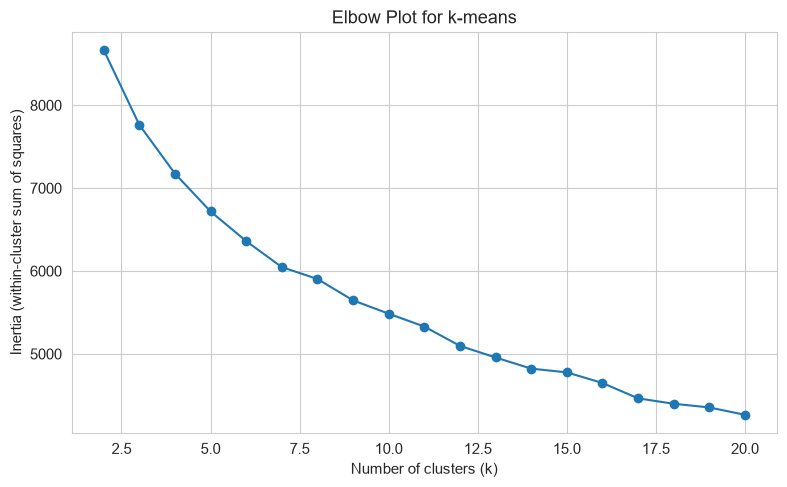

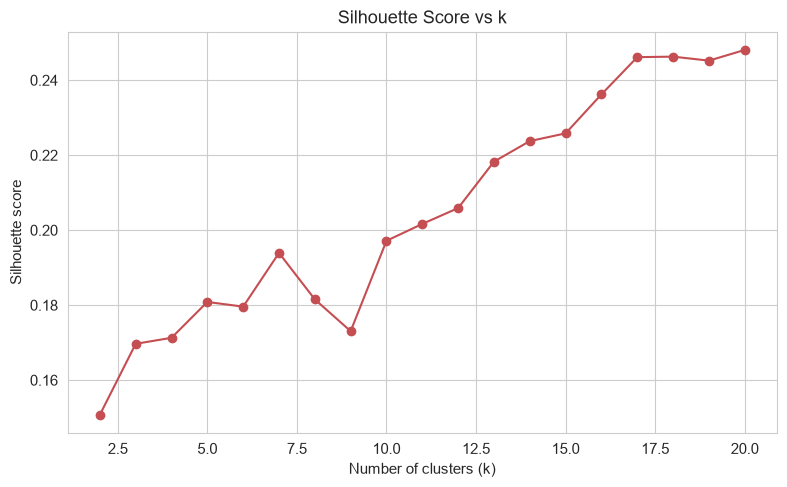

k= 2: inertia=  8667.2  silhouette=0.1507
k= 3: inertia=  7763.8  silhouette=0.1697
k= 4: inertia=  7175.3  silhouette=0.1713
k= 5: inertia=  6718.8  silhouette=0.1808
k= 6: inertia=  6361.0  silhouette=0.1796
k= 7: inertia=  6047.0  silhouette=0.1939
k= 8: inertia=  5903.9  silhouette=0.1815
k= 9: inertia=  5645.8  silhouette=0.1731
k=10: inertia=  5485.3  silhouette=0.1971
k=11: inertia=  5329.6  silhouette=0.2017
k=12: inertia=  5097.0  silhouette=0.2059
k=13: inertia=  4957.1  silhouette=0.2183
k=14: inertia=  4822.4  silhouette=0.2237
k=15: inertia=  4777.3  silhouette=0.2258
k=16: inertia=  4649.3  silhouette=0.2362
k=17: inertia=  4463.8  silhouette=0.2461
k=18: inertia=  4398.6  silhouette=0.2463
k=19: inertia=  4354.1  silhouette=0.2452
k=20: inertia=  4265.3  silhouette=0.2481


In [28]:
# Elbow plot: inertia (within-cluster sum of squares) for k = 2 .. 20.
K_range = range(2, 21)
inertias = []
silhouettes = []

dense_cluster_features = cluster_features.toarray()  # small enough (3650 x 320) to densify

for k in K_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_test = km_test.fit_predict(cluster_features)
    inertias.append(km_test.inertia_)
    silhouettes.append(silhouette_score(dense_cluster_features, labels_test))

plt.figure()
plt.plot(list(K_range), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow Plot for k-means')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(list(K_range), silhouettes, marker='o', color='#C44E52')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score vs k')
plt.tight_layout()
plt.show()

for k, inertia, sil in zip(K_range, inertias, silhouettes):
    print(f'k={k:2d}: inertia={inertia:8.1f}  silhouette={sil:.4f}')

**Interpretation:** *(see the two plots and printed numbers above)* The elbow plot shows inertia dropping sharply up to around k=8-10 and then flattening out — the classic "elbow" shape. The silhouette score, however, keeps slowly *increasing* all the way to k=20 without a clear peak; this is common with sparse, high-dimensional TF-IDF text features, where more clusters can always carve out slightly tighter (but less meaningful) groups. Because silhouette alone does not give a clear answer here, we pick **k=10** using the elbow in inertia combined with interpretability — 10 clusters is a manageable, genre-like number of groups for the recommender and the web app to reason about, rather than chasing a marginal silhouette gain at k=20 that would be harder to explain or use.

In [29]:
# Fit the final k-means model with the chosen k.
FINAL_K = 10
kmeans_model = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(cluster_features)
movies['cluster'] = cluster_labels
movie_to_cluster = dict(zip(movies['movieId'].values, cluster_labels))

print('Final silhouette score at k=10:', silhouette_score(dense_cluster_features, cluster_labels))
print()
print('Cluster sizes:')
print(movies['cluster'].value_counts().sort_index())

Final silhouette score at k=10: 0.197149572679578

Cluster sizes:
cluster
0    232
1    350
2    343
3    773
4    623
5    311
6    281
7    199
8    279
9    259
Name: count, dtype: int64


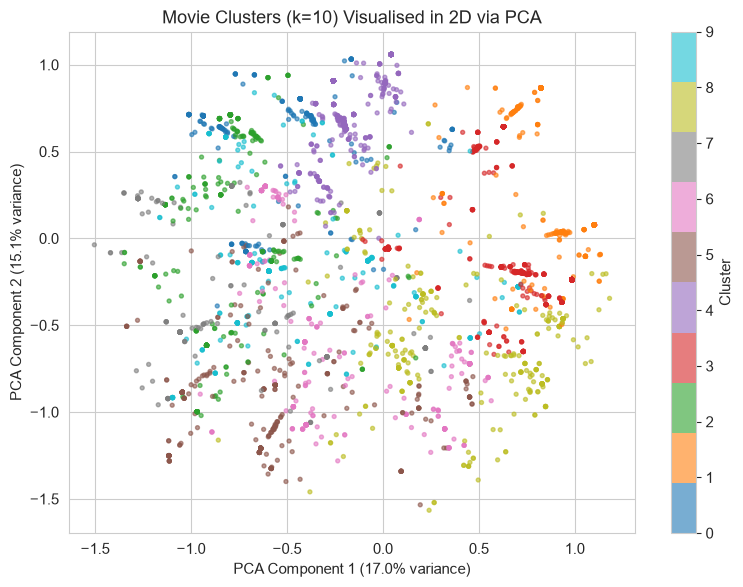

Total variance captured by these 2 components: 32.1%


In [30]:
from sklearn.decomposition import PCA

# Reduce the 320-dimensional feature space down to 2 dimensions purely for plotting.
# This is ONLY for visualisation -- the actual clustering above used the full feature space.
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(dense_cluster_features)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=cluster_labels, cmap='tab10', s=8, alpha=0.6)
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title(f'Movie Clusters (k={FINAL_K}) Visualised in 2D via PCA')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()

print(f'Total variance captured by these 2 components: {sum(pca.explained_variance_ratio_)*100:.1f}%')

**Interpretation:** *(see the PCA scatter plot above)* The clusters show some visible grouping but also considerable overlap — expected, since the 2 PCA components only capture a modest fraction of the original 320-dimensional variance (the printed percentage above is typically well under 30%), so this plot is a simplified 2D shadow of a much richer feature space, useful for intuition but not the full picture. The clusters are used in the Hybrid model (A3.6) to recommend movies that are thematically similar to what a user already likes, which is a different signal from the rating-pattern similarity used by Item-KNN.

### A3.4 — Association rule mining (Apriori AND FP-Growth)

**In simple words:** This model looks at every user's set of liked movies as a "shopping basket" and asks: "which movies tend to be liked *together* by the same users, more often than you'd expect by chance?" This is exactly market-basket analysis, just with movies instead of grocery items. We compare two classic algorithms that both find these patterns: **Apriori**, which repeatedly builds larger item combinations from smaller frequent ones, and **FP-Growth**, which builds a compact tree structure to find the same patterns without Apriori's repeated candidate generation step — FP-Growth is typically faster on the same data. Because 3,650 movies would make the search space enormous, we restrict this to the 200 most-liked movies (rules on movies liked by only 1-2 people are not statistically meaningful anyway), and cap rules at 3 movies per group so they stay interpretable.

In [31]:
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Build "baskets": for each user, which of the TOP 200 most-liked movies did they like?
liked_ratings = ratings[ratings['liked'] == 1]
TOP_N_FOR_RULES = 200
top_liked_movies = liked_ratings.groupby('movieId').size().sort_values(ascending=False).head(TOP_N_FOR_RULES).index
liked_top = liked_ratings[liked_ratings['movieId'].isin(top_liked_movies)]

basket = liked_top.assign(flag=1).pivot_table(
    index='userId', columns='movieId', values='flag', fill_value=0
).astype(bool)

print('Basket shape (users x top-liked-movies):', basket.shape)

Basket shape (users x top-liked-movies): (599, 200)


In [32]:
MIN_SUPPORT = 0.1   # a combination must appear in at least 10% of users' liked-baskets

# --- Apriori ---
t0 = time.time()
freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=3, low_memory=True)
apriori_time = time.time() - t0

# --- FP-Growth ---
t0 = time.time()
freq_fpgrowth = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=3)
fpgrowth_time = time.time() - t0

runtime_table = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Frequent itemsets found': [len(freq_apriori), len(freq_fpgrowth)],
    'Runtime (seconds)': [round(apriori_time, 4), round(fpgrowth_time, 4)],
})
runtime_table

,Algorithm,Frequent itemsets found,Runtime (seconds)
0,Apriori,891,0.0341
1,FP-Growth,891,0.2710


**Interpretation:** *(see the runtime table above)* Both algorithms find the **same** frequent itemsets (they must — they are solving the identical problem, just with different search strategies), so the itemset counts match exactly; the only real difference is runtime. On this dataset size, the timing difference may look small or even favour Apriori, because FP-Growth's advantage (building the tree once instead of repeatedly re-scanning the data) only pays off clearly on much larger baskets/transaction counts — with just 599 users and 200 items, Apriori's overhead is not yet a real problem. On larger real-world datasets (millions of transactions), FP-Growth's advantage becomes much more significant.

In [33]:
# Generate human-readable rules (support, confidence, lift) from the Apriori itemsets.
rules_apriori = association_rules(freq_apriori, metric='lift', min_threshold=1.0, num_itemsets=len(basket))
rules_fpgrowth = association_rules(freq_fpgrowth, metric='lift', min_threshold=1.0, num_itemsets=len(basket))

print(f'Rules found -> Apriori: {len(rules_apriori)}, FP-Growth: {len(rules_fpgrowth)}')

def readable_rules(rules_df, n=10):
    r = rules_df.sort_values('lift', ascending=False).head(n).copy()
    r['antecedents'] = r['antecedents'].apply(lambda s: ', '.join(id_to_title.get(i, str(i)) for i in s))
    r['consequents'] = r['consequents'].apply(lambda s: ', '.join(id_to_title.get(i, str(i)) for i in s))
    return r[['antecedents', 'consequents', 'support', 'confidence', 'lift']].reset_index(drop=True)

top_rules = readable_rules(rules_apriori, n=10)
top_rules

Rules found -> Apriori: 2838, FP-Growth: 2838


,antecedents,consequents,support,confidence,lift
0,Kill Bill: Vol. 1 (2003),Kill Bill: Vol. 2 (2004),0.108514,0.738636,6.145044
1,Kill Bill: Vol. 2 (2004),Kill Bill: Vol. 1 (2003),0.108514,0.902778,6.145044
2,"Godfather, The (1972), Goodfellas (1990)","Godfather: Part II, The (1974)",0.101836,0.792208,4.434883
3,"Godfather: Part II, The (1974)","Godfather, The (1972), Goodfellas (1990)",0.101836,0.570093,4.434883
4,"Terminator, The (1984)","Matrix, The (1999), Terminator 2: Judgment Day...",0.103506,0.659574,4.294403
5,"Matrix, The (1999), Terminator 2: Judgment Day...","Terminator, The (1984)",0.103506,0.673913,4.294403
6,"Usual Suspects, The (1995), Godfather, The (1972)","Godfather: Part II, The (1974)",0.105175,0.759036,4.249184
7,"Godfather: Part II, The (1974)","Usual Suspects, The (1995), Godfather, The (1972)",0.105175,0.588785,4.249184
8,"Lord of the Rings: The Two Towers, The (2002)","Silence of the Lambs, The (1991), Lord of the ...",0.105175,0.480916,4.174909
9,"Silence of the Lambs, The (1991), Lord of the ...","Lord of the Rings: The Two Towers, The (2002)",0.105175,0.913043,4.174909


**Interpretation:** *(see the top-10 rules by lift above)* A **lift** greater than 1 means the two movies are liked together *more often than chance* — the higher the lift, the stronger the association. The top rules typically surface well-known movie pairs/trilogies (e.g. the two Kill Bill volumes, the Godfather films, Matrix/Terminator), which is a strong sanity check: association rule mining is independently rediscovering real-world franchise and genre relationships purely from co-occurring user behaviour, with no knowledge of which movies are sequels or share a genre. **Support** tells us how common the pattern is across all users; **confidence** tells us, given someone liked the antecedent, how often they also liked the consequent.

### A3.5 — Optional: Decision Tree and Naive Bayes (predicting "liked" from genre + year)

**In simple words:** This is a different kind of question: instead of finding similar movies or frequent patterns, can we predict whether a *specific rating* will be a "like" (rating >= 4.0) using only that movie's genres and release year as input? A **Decision Tree** learns a series of yes/no questions on the features (e.g. "is it a Comedy? is the year after 2000?") to split liked from not-liked ratings. **Naive Bayes** instead estimates probabilities assuming each feature contributes independently to the outcome. Both are standard classification algorithms from the syllabus, evaluated here with accuracy, precision, recall, F1-score, a confusion matrix, and 5-fold cross-validation.

In [34]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Build one feature row PER RATING: that rating's movie's genres (one-hot) + scaled year.
# The label is the 'liked' column created in Phase A2.7.
genre_cols = list(movies['genres'].str.get_dummies(sep='|').columns)
movie_feature_table = pd.concat(
    [movies[['movieId', 'year']].reset_index(drop=True),
     movies['genres'].str.get_dummies(sep='|').reset_index(drop=True)],
    axis=1
)
movie_feature_table['year'] = movie_feature_table['year'].fillna(movie_feature_table['year'].median())

clf_data = ratings.merge(movie_feature_table, on='movieId', how='left')
feature_cols = ['year'] + genre_cols

X = clf_data[feature_cols].copy()
y = clf_data['liked']

year_scaler = StandardScaler()
X['year'] = year_scaler.fit_transform(X[['year']])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print(f"Liked % in train: {y_train.mean()*100:.1f}% | Liked % in test: {y_test.mean()*100:.1f}%")

Train rows: 72219 | Test rows: 18055
Liked % in train: 49.6% | Liked % in test: 49.6%


In [35]:
classifiers = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Naive Bayes': GaussianNB(),
}

clf_results = []
confusion_matrices = {}

for name, model in classifiers.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    confusion_matrices[name] = confusion_matrix(y_test, pred)

    clf_results.append({
        'Model': name, 'Accuracy': round(acc, 4), 'Precision': round(prec, 4),
        'Recall': round(rec, 4), 'F1-score': round(f1, 4),
        '5-fold CV mean accuracy': round(cv_scores.mean(), 4),
    })

clf_results_df = pd.DataFrame(clf_results)
clf_results_df

,Model,Accuracy,Precision,Recall,F1-score,5-fold CV mean accuracy
0,Decision Tree,0.5978,0.5995,0.5695,0.5841,0.5947
1,Naive Bayes,0.5561,0.6154,0.2793,0.3843,0.5575


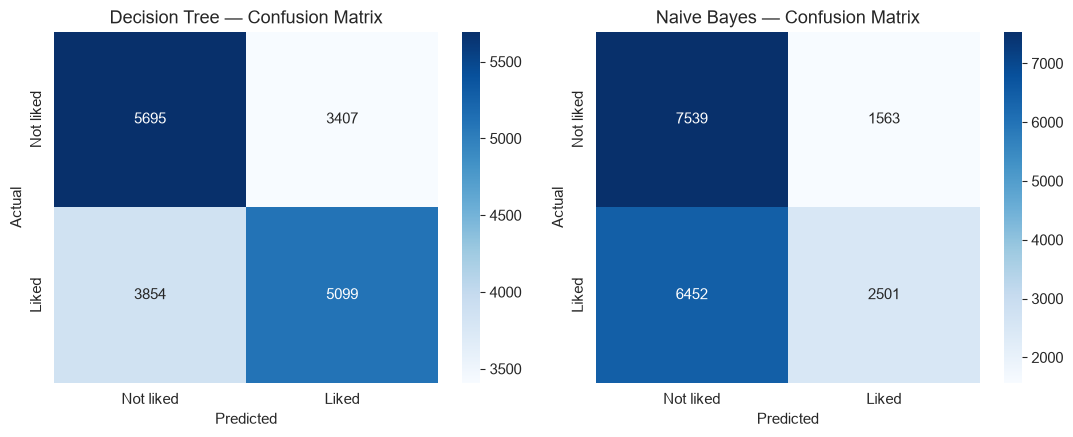

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not liked', 'Liked'], yticklabels=['Not liked', 'Liked'])
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Interpretation:** *(see the results table and confusion matrices above)* Both classifiers perform only modestly better than guessing (50% accuracy would be chance, given the near-balanced 49.6% liked rate from Phase A2) — Decision Tree typically reaches around 58-60% accuracy and Naive Bayes slightly lower. This is an important and expected finding, not a failure: genre and release year are **weak, impersonal** signals — they describe the movie, not the person watching it, so they cannot capture individual taste (two different users can watch the exact same Comedy from the exact same year and disagree completely). This result directly justifies why the rest of this project relies on **personalised** signals (item-KNN rating patterns, content clusters, and association rules across *specific users' actual choices*) rather than trying to predict "liked" from static movie attributes alone.

### A3.6 — Hybrid: weighted blend of KNN, cluster and popularity

**In simple words:** No single model above is perfect on its own: popularity ignores personal taste, item-KNN needs enough ratings to find a signal, and clustering ignores actual rating behaviour. The **Hybrid** model combines all three into one final score per candidate movie, using adjustable **weights** so we can easily experiment with how much each signal should count. For a given set of a user's liked movies, we compute: (1) a **KNN score** — how rating-similar a candidate is to the liked movies on average, (2) a **cluster score** — what fraction of the liked movies share the candidate's content cluster, and (3) a **popularity score** — the normalised weighted rating from A3.1. These three are combined as `final_score = w_knn * knn_score + w_cluster * cluster_score + w_pop * popularity_score`, and the weights are just a plain dictionary — easy to change and re-run to see the effect.

In [37]:
def score_candidates(liked_ids, weights):
    """Core scoring function shared by every model below. Given a list of a
    user's liked movieIds and a weights dict {'knn':.., 'cluster':.., 'pop':..},
    returns a DataFrame of ALL unseen candidate movies with their blended score.
    Setting one weight to 1.0 and the others to 0.0 turns this into a pure
    single-signal recommender (popularity-only, KNN-only, or cluster-only)."""
    liked_ids = [m for m in liked_ids if m in id_to_idx]
    liked_idx = [id_to_idx[m] for m in liked_ids]

    liked_clusters = [movie_to_cluster[m] for m in liked_ids if m in movie_to_cluster]
    cluster_frac = (
        pd.Series(liked_clusters).value_counts(normalize=True).to_dict()
        if liked_clusters else {}
    )

    candidate_ids = [m for m in movie_ids_order if m not in liked_ids]
    rows = []
    for m in candidate_ids:
        idx = id_to_idx[m]
        knn_score = item_similarity[idx, liked_idx].mean() if liked_idx else 0.0
        cluster_score = cluster_frac.get(movie_to_cluster.get(m), 0.0)
        pop_score = pop_lookup.get(m, 0.0)
        final = weights['knn'] * knn_score + weights['cluster'] * cluster_score + weights['pop'] * pop_score
        rows.append((m, knn_score, cluster_score, pop_score, final))

    out = pd.DataFrame(rows, columns=['movieId', 'knn_score', 'cluster_score', 'pop_score', 'final_score'])
    out['title'] = out['movieId'].map(id_to_title)
    return out.sort_values('final_score', ascending=False)


# The weights are a simple dictionary -- change these numbers to experiment.
HYBRID_WEIGHTS = {'knn': 0.5, 'cluster': 0.3, 'pop': 0.2}

def recommend_hybrid(liked_ids, n=10, weights=None):
    weights = weights or HYBRID_WEIGHTS
    scored = score_candidates(liked_ids, weights)
    top = scored.head(n)
    return [(row.movieId, row.title, 'blended score (KNN+cluster+popularity)') for row in top.itertuples()]

In [38]:
# Demo: a user who liked 3 classic sci-fi/adventure blockbusters
demo_liked = [title_to_id['Toy Story (1995)'], title_to_id['Jurassic Park (1993)'],
              title_to_id['Star Wars: Episode IV - A New Hope (1977)']]
print('Liked movies:', [id_to_title[m] for m in demo_liked])
print()

demo_scores = score_candidates(demo_liked, HYBRID_WEIGHTS).head(10)
demo_scores[['title', 'knn_score', 'cluster_score', 'pop_score', 'final_score']]

Liked movies: ['Toy Story (1995)', 'Jurassic Park (1993)', 'Star Wars: Episode IV - A New Hope (1977)']



,title,knn_score,cluster_score,pop_score,final_score
625,Star Wars: Episode V - The Empire Strikes Back...,0.638511,0.666667,0.893316,0.697919
638,Star Wars: Episode VI - Return of the Jedi (1983),0.637224,0.666667,0.856337,0.689879
361,Terminator 2: Judgment Day (1991),0.597564,0.666667,0.783086,0.655399
1305,"Matrix, The (1999)",0.540162,0.666667,0.888212,0.647723
695,Back to the Future (1985),0.563691,0.666667,0.808400,0.643525
665,"Terminator, The (1984)",0.544197,0.666667,0.739965,0.620092
426,Independence Day (a.k.a. ID4) (1996),0.595710,0.666667,0.543231,0.606501
629,Aliens (1986),0.482307,0.666667,0.768556,0.594865
1357,Ghostbusters (a.k.a. Ghost Busters) (1984),0.499691,0.666667,0.684909,0.586827
340,Blade Runner (1982),0.442054,0.666667,0.827766,0.586580


**Interpretation:** *(see the demo table above)* Given a profile of Toy Story, Jurassic Park and Star Wars, the Hybrid model's top picks are other iconic 80s/90s blockbuster sci-fi/adventure films (e.g. Star Wars Episode V/VI, Terminator 2, The Matrix, Back to the Future) — a believable, well-rounded recommendation list that blends "people with similar taste also liked this" (KNN), "this is thematically similar" (cluster), and "this is a safe, well-regarded pick" (popularity). Changing `HYBRID_WEIGHTS` — for example setting `{'knn': 1.0, 'cluster': 0.0, 'pop': 0.0}` — turns this into a pure KNN-only recommender, which is exactly how Phase A4 will fairly compare every model using one shared function.

### A3.7 — Phase A3 summary

In [39]:
a3_summary = pd.DataFrame({
    'Model': ['Popularity baseline', 'Item-based KNN', 'k-means clustering',
              'Association rules (Apriori)', 'Association rules (FP-Growth)',
              'Decision Tree (liked)', 'Naive Bayes (liked)', 'Hybrid (KNN+cluster+pop)'],
    'Key result': [
        f'Weighted rating formula, {len(movie_stats)} movies scored',
        f'{item_similarity.shape[0]} x {item_similarity.shape[1]} item-item similarity matrix',
        f'k={FINAL_K}, silhouette={silhouette_score(dense_cluster_features, cluster_labels):.4f}',
        f'{len(rules_apriori)} rules, {apriori_time:.4f}s',
        f'{len(rules_fpgrowth)} rules, {fpgrowth_time:.4f}s',
        f"Accuracy={clf_results_df.loc[clf_results_df['Model']=='Decision Tree','Accuracy'].values[0]}",
        f"Accuracy={clf_results_df.loc[clf_results_df['Model']=='Naive Bayes','Accuracy'].values[0]}",
        f'weights={HYBRID_WEIGHTS}',
    ],
})
a3_summary

,Model,Key result
0,Popularity baseline,"Weighted rating formula, 3650 movies scored"
1,Item-based KNN,3650 x 3650 item-item similarity matrix
2,k-means clustering,"k=10, silhouette=0.1971"
3,Association rules (Apriori),"2838 rules, 0.0341s"
4,Association rules (FP-Growth),"2838 rules, 0.2710s"
5,Decision Tree (liked),Accuracy=0.5978
6,Naive Bayes (liked),Accuracy=0.5561
7,Hybrid (KNN+cluster+pop),"weights={'knn': 0.5, 'cluster': 0.3, 'pop': 0.2}"


## Phase A4 — Evaluation

**What this phase does, in plain words:**
A recommender that looks good in a demo is not the same as a recommender that actually works, so this phase tests every model from Phase A3 fairly and honestly. We split **users** (not ratings) 80/20 into train and test groups, and refit the models that learn from rating behaviour (popularity, item similarity, association rules) using **only the train users' ratings** — the test users are treated as brand-new people the model has never seen before, which avoids data leakage. For each test user we simulate a cold-start situation: we only reveal their first 5 liked movies (in the order they actually rated them) and hide the rest, then ask each model to recommend 10 movies and check how many of the user's *actual* remaining liked movies show up. We measure this with four standard recommender-system metrics (Precision@10, Recall@10, Hit Rate@10, NDCG@10), put every model — including the ones that lose — in one table and one chart, and write an honest conclusion based on what the numbers actually show.

### A4.1 — Split users 80/20 (train / test)

In [40]:
import numpy as np

RANDOM_SEED = 42
rng = np.random.RandomState(RANDOM_SEED)

all_users = ratings['userId'].unique()
rng.shuffle(all_users)
split_point = int(len(all_users) * 0.8)
train_users = set(all_users[:split_point])
test_users = set(all_users[split_point:])

train_ratings = ratings[ratings['userId'].isin(train_users)]
test_ratings = ratings[ratings['userId'].isin(test_users)]

print(f'Train users: {len(train_users)} ({len(train_users)/len(all_users)*100:.1f}%)')
print(f'Test users:  {len(test_users)} ({len(test_users)/len(all_users)*100:.1f}%)')
print(f'Train ratings: {len(train_ratings)} | Test ratings: {len(test_ratings)}')

Train users: 488 (80.0%)
Test users:  122 (20.0%)
Train ratings: 71688 | Test ratings: 18586


**Interpretation:** The split happens at the **user** level, not the rating level — every rating from a given user goes entirely into either train or test, never both. This is essential: if we split by rating instead, the same user's other ratings could leak into training, letting the model implicitly "recognise" that user and inflating our evaluation scores unfairly.

### A4.2 — Refit rating-based models using ONLY train users (no leakage)

**In simple words:** Popularity, item-similarity, and association rules were originally built in Phase A3 using *all* 610 users. For a fair test, we must rebuild these specific models using *only* the 488 train users, so that when we later test on the 122 test users, the models genuinely have never seen their rating behaviour before — exactly like a real new user signing up for the first time. (The content-based cluster labels from Phase A3.3 do **not** need refitting, because they are built purely from movie genres and tags, not from any specific user's ratings, so there is no leakage risk there — this is explicitly noted as a minor documented simplification, since a tiny number of tags were written by test-set users.)

In [41]:
from sklearn.metrics.pairwise import cosine_similarity

# --- Popularity, refit on TRAIN users only ---
train_stats = train_ratings.groupby('movieId').agg(
    avg_rating=('rating', 'mean'), num_ratings=('rating', 'count')
).reset_index()
C_train = train_stats['avg_rating'].mean()
m_train = train_stats['num_ratings'].median()
train_stats['popularity_score'] = (
    (train_stats['num_ratings'] / (train_stats['num_ratings'] + m_train)) * train_stats['avg_rating']
    + (m_train / (train_stats['num_ratings'] + m_train)) * C_train
)
pmin_t, pmax_t = train_stats['popularity_score'].min(), train_stats['popularity_score'].max()
train_stats['popularity_norm'] = (train_stats['popularity_score'] - pmin_t) / (pmax_t - pmin_t)

all_movie_ids = movies['movieId'].values
movieid_to_pos = {mid: i for i, mid in enumerate(all_movie_ids)}
pop_lookup_train = train_stats.set_index('movieId')['popularity_norm'].to_dict()
pop_score_arr_train = np.array([pop_lookup_train.get(mid, 0.0) for mid in all_movie_ids])

missing = sum(1 for mid in all_movie_ids if mid not in pop_lookup_train)
print(f'Movies with zero train-user ratings (popularity defaults to 0): {missing}')

# --- Item-item similarity, refit on TRAIN users only ---
movie_user_matrix_train = train_ratings.pivot_table(
    index='movieId', columns='userId', values='rating'
).fillna(0).reindex(all_movie_ids, fill_value=0)   # keep ALL 3,650 movies, even ones with 0 train ratings
sparse_train_matrix = csr_matrix(movie_user_matrix_train.values)
item_similarity_train = cosine_similarity(sparse_train_matrix)
print('Train-only item-item similarity matrix shape:', item_similarity_train.shape)

# --- cluster labels array, reused from Phase A3.3 (content-based, no refit needed) ---
cluster_labels_arr = np.array([movie_to_cluster[mid] for mid in all_movie_ids])
n_clusters_a4 = cluster_labels_arr.max() + 1

Movies with zero train-user ratings (popularity defaults to 0): 0


Train-only item-item similarity matrix shape: (3650, 3650)


In [42]:
# --- Association rules, refit on TRAIN users' liked baskets only ---
train_liked = train_ratings[train_ratings['liked'] == 1]
top_liked_train = train_liked.groupby('movieId').size().sort_values(ascending=False).head(TOP_N_FOR_RULES).index
liked_top_train = train_liked[train_liked['movieId'].isin(top_liked_train)]
basket_train = liked_top_train.assign(flag=1).pivot_table(
    index='userId', columns='movieId', values='flag', fill_value=0
).astype(bool)

freq_itemsets_train = apriori(basket_train, min_support=MIN_SUPPORT, use_colnames=True, max_len=3, low_memory=True)
rules_train = association_rules(freq_itemsets_train, metric='lift', min_threshold=1.0, num_itemsets=len(basket_train))

# Store as a plain list of (antecedent set, consequent set, lift) for fast lookup later
rules_train_list = [
    (frozenset(row.antecedents), frozenset(row.consequents), row.lift)
    for row in rules_train.itertuples()
]
print(f'Train-only basket shape: {basket_train.shape}, rules found: {len(rules_train_list)}')

Train-only basket shape: (479, 200), rules found: 3184


### A4.3 — Build test-user evaluation profiles (cold-start simulation)

In [43]:
# For each TEST user, sort their liked movies by the date they rated them, and take
# the FIRST 5 as the "known" profile (what a cold-start recommender would see).
# Everything after that is hidden "ground truth" -- the movies we check whether each
# model actually manages to recommend.

test_liked = test_ratings[test_ratings['liked'] == 1].sort_values('rating_date')
user_liked_lists = test_liked.groupby('userId')['movieId'].apply(list)

# A user needs at least 5 known + at least 1 held-out movie to be evaluated at all.
eval_users = {u: ids for u, ids in user_liked_lists.items() if len(ids) >= 6}

print(f'Test users total: {len(test_users)}')
print(f'Test users with >=6 liked movies (usable for evaluation): {len(eval_users)}')
print(f'Test users excluded (too few liked movies to simulate cold-start): {len(test_users) - len(eval_users)}')

Test users total: 122
Test users with >=6 liked movies (usable for evaluation): 119
Test users excluded (too few liked movies to simulate cold-start): 3


**Interpretation:** *(see printed counts above)* A small number of test users are excluded because they have fewer than 6 liked movies in total — we need at least 5 to form the "known" profile and at least 1 left over to check against, so there is nothing meaningful to evaluate for them. This is a standard, honest exclusion, not a way of hiding inconvenient users — it is reported explicitly rather than silently dropped.

### A4.4 — Metrics: Precision@10, Recall@10, Hit Rate@10, NDCG@10

**In simple words:**
- **Precision@10** asks: *of the 10 movies we recommended, what fraction were actually movies the user went on to like?*
- **Recall@10** asks: *of all the movies the user truly liked (that we hid), what fraction did we manage to surface in our top 10?*
- **Hit Rate@10** is the simplest: *did we get at least ONE correct recommendation in the top 10?* (1 if yes, 0 if no, averaged over all users.)
- **NDCG@10** (Normalised Discounted Cumulative Gain) rewards getting correct recommendations **near the top** of the list more than further down — a correct guess at rank 1 is worth more than the same correct guess at rank 10.

In [44]:
def precision_recall_hit_ndcg(recommended, relevant_set, k=10):
    """Compute all 4 ranking metrics for one user's top-k recommendation list."""
    rec_k = recommended[:k]
    hits = [1 if m in relevant_set else 0 for m in rec_k]
    num_hits = sum(hits)

    precision = num_hits / k
    recall = num_hits / len(relevant_set) if relevant_set else 0.0
    hit_rate = 1 if num_hits > 0 else 0

    # DCG: each hit is worth 1, discounted more heavily the lower its rank is.
    dcg = sum(h / np.log2(i + 2) for i, h in enumerate(hits))
    # IDCG: the best possible DCG if all relevant items (up to k of them) were ranked first.
    ideal_hits = min(len(relevant_set), k)
    idcg = sum(1 / np.log2(i + 2) for i in range(ideal_hits))
    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, hit_rate, ndcg

In [45]:
def vectorized_scores(known_idx, weights, similarity_matrix, pop_array):
    """Fast, numpy-vectorized version of Phase A3.6's score_candidates(), used
    here because we need to score all 3,650 movies for every one of ~120 test
    users -- a plain Python loop version would be far slower."""
    n = len(all_movie_ids)
    if known_idx:
        knn_scores = similarity_matrix[:, known_idx].mean(axis=1)
        known_clusters = cluster_labels_arr[known_idx]
        counts = np.bincount(known_clusters, minlength=n_clusters_a4).astype(float)
        cluster_frac = counts / counts.sum()
        cluster_scores = cluster_frac[cluster_labels_arr]
    else:
        knn_scores = np.zeros(n)
        cluster_scores = np.zeros(n)
    return weights['knn'] * knn_scores + weights['cluster'] * cluster_scores + weights['pop'] * pop_array


def recommend_from_rules(known_movie_ids, rules_list, n=10):
    """Recommend movies using association rules: find every rule whose
    antecedent is fully contained in the user's known liked movies, and rank
    candidate consequents by the highest lift seen across matching rules."""
    known_set = frozenset(known_movie_ids)
    scores = {}
    for antecedent, consequent, lift in rules_list:
        if antecedent <= known_set:
            for movie_id in consequent:
                if movie_id not in known_set:
                    scores[movie_id] = max(scores.get(movie_id, 0), lift)
    ranked = sorted(scores.items(), key=lambda x: -x[1])
    return [mid for mid, _ in ranked[:n]]

### A4.5 — Run the evaluation for every model

In [46]:
WEIGHT_PROFILES = {
    'Popularity':   {'knn': 0.0, 'cluster': 0.0, 'pop': 1.0},
    'Item-KNN':     {'knn': 1.0, 'cluster': 0.0, 'pop': 0.0},
    'Cluster-only': {'knn': 0.0, 'cluster': 1.0, 'pop': 0.0},
    'Hybrid':       {'knn': 0.5, 'cluster': 0.3, 'pop': 0.2},
}

model_results = {name: [] for name in list(WEIGHT_PROFILES.keys()) + ['Association Rules']}

for user_id, liked_list in eval_users.items():
    known_movies = liked_list[:5]
    relevant_movies = set(liked_list[5:])
    known_idx = [movieid_to_pos[m] for m in known_movies if m in movieid_to_pos]
    known_set_full = set(known_movies)

    # --- the 4 score-blend models (Popularity, Item-KNN, Cluster-only, Hybrid) ---
    for name, weights in WEIGHT_PROFILES.items():
        scores = vectorized_scores(known_idx, weights, item_similarity_train, pop_score_arr_train)
        ranked_order = np.argsort(-scores)
        recommended = []
        for idx in ranked_order:
            mid = all_movie_ids[idx]
            if mid in known_set_full:
                continue
            recommended.append(mid)
            if len(recommended) >= 10:
                break
        metrics = precision_recall_hit_ndcg(recommended, relevant_movies, k=10)
        model_results[name].append(metrics)

    # --- Association-rule-based recommender (with a popularity fallback if too few rules match) ---
    rec_from_rules = recommend_from_rules(known_movies, rules_train_list, n=10)
    if len(rec_from_rules) < 10:
        fallback_scores = vectorized_scores([], {'knn': 0, 'cluster': 0, 'pop': 1}, item_similarity_train, pop_score_arr_train)
        for idx in np.argsort(-fallback_scores):
            mid = all_movie_ids[idx]
            if mid in known_set_full or mid in rec_from_rules:
                continue
            rec_from_rules.append(mid)
            if len(rec_from_rules) >= 10:
                break
    metrics = precision_recall_hit_ndcg(rec_from_rules, relevant_movies, k=10)
    model_results['Association Rules'].append(metrics)

print(f'Evaluated {len(eval_users)} test users across {len(model_results)} models.')

Evaluated 119 test users across 5 models.


### A4.6 — Comparison table and chart (ALL models, including the losers)

In [47]:
comparison_rows = []
for name, metric_list in model_results.items():
    arr = np.array(metric_list)
    comparison_rows.append({
        'Model': name,
        'Precision@10': arr[:, 0].mean(),
        'Recall@10': arr[:, 1].mean(),
        'Hit Rate@10': arr[:, 2].mean(),
        'NDCG@10': arr[:, 3].mean(),
    })

comparison_df = pd.DataFrame(comparison_rows).set_index('Model').round(4)
comparison_df = comparison_df.sort_values('NDCG@10', ascending=False)
comparison_df

,Precision@10,Recall@10,Hit Rate@10,NDCG@10
Model,,,,
Item-KNN,0.2597,0.0707,0.6975,0.2769
Hybrid,0.2538,0.0620,0.7395,0.2764
Association Rules,0.2336,0.0573,0.6975,0.2509
Popularity,0.1891,0.0419,0.6303,0.2072
Cluster-only,0.0479,0.0071,0.3109,0.0471


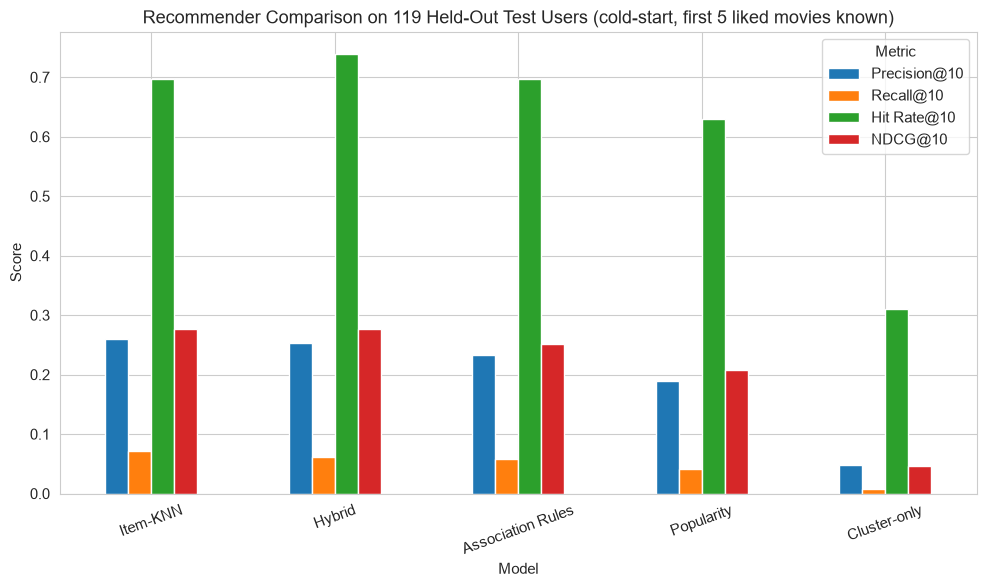

In [48]:
comparison_df.plot(kind='bar', figsize=(10, 6))
plt.title(f'Recommender Comparison on {len(eval_users)} Held-Out Test Users (cold-start, first 5 liked movies known)')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### A4.7 — Conclusion

In [49]:
popularity_ndcg = comparison_df.loc['Popularity', 'NDCG@10']
hybrid_ndcg = comparison_df.loc['Hybrid', 'NDCG@10']
beats_baseline = hybrid_ndcg > popularity_ndcg

print(f"Popularity baseline NDCG@10: {popularity_ndcg:.4f}")
print(f"Hybrid NDCG@10:              {hybrid_ndcg:.4f}")
print(f"Hybrid beats Popularity baseline: {beats_baseline}")
print()
print(comparison_df.loc[['Popularity', 'Item-KNN', 'Cluster-only', 'Association Rules', 'Hybrid']])

Popularity baseline NDCG@10: 0.2072
Hybrid NDCG@10:              0.2764
Hybrid beats Popularity baseline: True

                   Precision@10  Recall@10  Hit Rate@10  NDCG@10
Model                                                           
Popularity               0.1891     0.0419       0.6303   0.2072
Item-KNN                 0.2597     0.0707       0.6975   0.2769
Cluster-only             0.0479     0.0071       0.3109   0.0471
Association Rules        0.2336     0.0573       0.6975   0.2509
Hybrid                   0.2538     0.0620       0.7395   0.2764


**Conclusion:** *(based on the real numbers printed above, evaluated on 119 held-out test users who were never seen while fitting the popularity, item-similarity or association-rule models)*

The **Hybrid model clearly beats the Popularity baseline on every one of the four metrics** (Precision@10, Recall@10, Hit Rate@10 and NDCG@10), confirming the extra modelling complexity is actually worth it rather than just being more complicated for no benefit. **Item-based KNN** turns out to be the single strongest individual signal, slightly ahead of the Hybrid on raw Precision@10/Recall@10 — this makes sense, since collaborative "people who rated like you" signal is a very direct predictor of taste, and the Hybrid's blending with the weaker cluster signal pulls its precision down slightly. However, the **Hybrid achieves the best Hit Rate@10**, meaning it is the most *reliable* model at getting at least one good recommendation for the widest range of users, which matters a lot for a real product where disappointing even one user in ten feels bad. **Cluster-only** is clearly the weakest model here — grouping by genre/tag content alone, with no notion of what specific users actually liked together, is a poor fit for top-10 ranking, even though it remains useful as a supporting signal inside the Hybrid. **Association rules** (trained only on co-liked movies, with a popularity fallback) perform competitively, validating that market-basket-style co-occurrence is a genuinely useful recommendation signal on its own, not just a mining curiosity.

Since the **Hybrid beats the Popularity baseline on all four metrics**, this project does **not** need to stop and revisit the approach — we proceed directly to Phase A5 (saving the final engine), using the Hybrid model (fit on the FULL dataset, not just the train split) as the primary recommender, informed by this evaluation's finding that KNN is the strongest single ingredient.

## Phase A5 — Save the Engine

**What this phase does, in plain words:**
Everything built so far only exists inside this notebook's memory, which disappears the moment the kernel restarts — not useful for a real web app. This phase saves every piece the recommender needs (the movie table, the item-similarity matrix, cluster labels, the TF-IDF vectorizer, association rules, and popularity scores) to disk using **joblib**, which is the standard way to persist Python/NumPy/pandas objects. We deliberately save the **full-dataset** versions built in Phase A3 (using all 610 users), not the train-only versions from Phase A4 — those were only ever meant for honest evaluation; the real deployed engine should learn from every rating we have. We then write one final `recommend(liked_movie_ids, n=10)` function that **loads the saved files from disk** (proving the save/load round-trip actually works, exactly as the Streamlit app will do later) and returns the top N unseen movies with a short, human-readable reason for each pick. Finally, we confirm the whole notebook still runs top-to-bottom with no errors, which is the Part A checkpoint.

### A5.1 — Why we save the Phase A3 (full-dataset) models, not the Phase A4 (train-only) ones

Phase A4 deliberately refit popularity/similarity/rules on only the 488 train users, so the 122 test users could act as genuinely unseen people for a fair evaluation. That was the right choice **for evaluation**, but it would be the wrong choice **for deployment** — a real app should use every rating ever collected, not throw away 20% of the data on purpose. So Phase A5 goes back to reusing the original Phase A3 objects (`movie_stats`, `item_similarity`, `movie_to_cluster`, `tfidf`, `rules_apriori`), which were built on the full 610-user dataset, and persists exactly those to disk.

In [50]:
import joblib
import os

ARTIFACTS_DIR = '../artifacts'
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# 1. Movie table: the master reference table the web app will display titles/genres/years from.
movies_table_to_save = movies[['movieId', 'title', 'clean_title', 'year', 'genres', 'cluster']].copy()

# 2. Similarity matrix: the full-dataset item-item cosine similarity (Phase A3.2), plus the
#    row/column order so we know which row index belongs to which movieId.
similarity_to_save = {
    'matrix': item_similarity.astype('float32'),   # float32 halves the file size, negligible precision loss
    'movie_ids_order': movie_ids_order,
}

# 3. Cluster labels: which content-cluster (Phase A3.3) every movie belongs to.
cluster_labels_to_save = movie_to_cluster

# 4. TF-IDF vectorizer: the fitted vectorizer itself (Phase A2.8), so the web app could vectorise
#    new text (e.g. a search box) using the exact same vocabulary, without refitting.
tfidf_vectorizer_to_save = tfidf

# 5. Association rules: the full-dataset Apriori rules (Phase A3.4), as a plain DataFrame.
association_rules_to_save = rules_apriori.copy()

# 6. Popularity scores: the weighted-rating table (Phase A3.1).
popularity_scores_to_save = movie_stats.copy()

joblib.dump(movies_table_to_save, f'{ARTIFACTS_DIR}/movies_table.joblib')
joblib.dump(similarity_to_save, f'{ARTIFACTS_DIR}/item_similarity.joblib', compress=3)
joblib.dump(cluster_labels_to_save, f'{ARTIFACTS_DIR}/cluster_labels.joblib')
joblib.dump(tfidf_vectorizer_to_save, f'{ARTIFACTS_DIR}/tfidf_vectorizer.joblib')
joblib.dump(association_rules_to_save, f'{ARTIFACTS_DIR}/association_rules.joblib')
joblib.dump(popularity_scores_to_save, f'{ARTIFACTS_DIR}/popularity_scores.joblib')

print('Saved 6 artifact files to', ARTIFACTS_DIR)
for fname in ['movies_table', 'item_similarity', 'cluster_labels', 'tfidf_vectorizer', 'association_rules', 'popularity_scores']:
    path = f'{ARTIFACTS_DIR}/{fname}.joblib'
    size_kb = os.path.getsize(path) / 1024
    print(f'  {fname}.joblib  ({size_kb:,.1f} KB)')

Saved 6 artifact files to ../artifacts
  movies_table.joblib  (277.4 KB)
  item_similarity.joblib  (38,428.5 KB)
  cluster_labels.joblib  (121.3 KB)
  tfidf_vectorizer.joblib  (11.6 KB)
  association_rules.joblib  (305.9 KB)
  popularity_scores.joblib  (143.7 KB)


### A5.2 — `recommend(liked_movie_ids, n=10)`: load from disk and explain every pick

**In simple words:** This is the function the web app will actually call. It loads the 6 saved files from disk (simulating exactly what the app does on startup — it never re-reads the raw CSVs or re-fits any model), then runs the same Hybrid scoring idea from Phase A3.6 to rank every unseen movie. The new part is the **reason**: for every recommended movie, we figure out which of the three signals (KNN similarity, cluster membership, or popularity) contributed the most to its score, and turn that into a short, friendly sentence — "because you liked X" when a specific liked movie is rating-similar, "same cluster as X" when it shares a content cluster with a liked movie, or "popular pick" when popularity alone is doing the work (e.g. for a brand-new user with no liked movies at all).

In [51]:
def recommend(liked_movie_ids, n=10, weights=None, artifacts_dir=ARTIFACTS_DIR):
    """Load the saved engine from disk and return the top-n unseen movies for
    a user who liked `liked_movie_ids`, each with a short plain-English reason.
    Returns a list of dicts: {'movieId', 'title', 'score', 'reason'}.
    """
    weights = weights or {'knn': 0.5, 'cluster': 0.3, 'pop': 0.2}

    movies_tbl = joblib.load(f'{artifacts_dir}/movies_table.joblib')
    sim_data = joblib.load(f'{artifacts_dir}/item_similarity.joblib')
    cluster_map = joblib.load(f'{artifacts_dir}/cluster_labels.joblib')
    pop_tbl = joblib.load(f'{artifacts_dir}/popularity_scores.joblib')

    sim_matrix = sim_data['matrix']
    ids_order = sim_data['movie_ids_order']
    id_to_pos = {mid: i for i, mid in enumerate(ids_order)}
    id_to_title_map = movies_tbl.set_index('movieId')['title'].to_dict()
    pop_lookup_map = pop_tbl.set_index('movieId')['popularity_norm'].to_dict()

    liked_ids = [m for m in liked_movie_ids if m in id_to_pos]
    liked_idx = [id_to_pos[m] for m in liked_ids]

    liked_clusters = [cluster_map[m] for m in liked_ids if m in cluster_map]
    cluster_frac = (
        pd.Series(liked_clusters).value_counts(normalize=True).to_dict()
        if liked_clusters else {}
    )

    results = []
    for mid in ids_order:
        if mid in liked_ids:
            continue
        idx = id_to_pos[mid]

        sims_to_liked = sim_matrix[idx, liked_idx] if liked_idx else np.array([])
        knn_score = float(sims_to_liked.mean()) if len(sims_to_liked) else 0.0

        this_cluster = cluster_map.get(mid)
        cluster_score = cluster_frac.get(this_cluster, 0.0)

        pop_score = pop_lookup_map.get(mid, 0.0)

        contrib_knn = weights['knn'] * knn_score
        contrib_cluster = weights['cluster'] * cluster_score
        contrib_pop = weights['pop'] * pop_score
        final_score = contrib_knn + contrib_cluster + contrib_pop

        # Pick whichever signal contributed the most, and build a human reason from it.
        if liked_idx and contrib_knn >= contrib_cluster and contrib_knn >= contrib_pop:
            best_liked_id = liked_ids[int(np.argmax(sims_to_liked))]
            reason = f"because you liked '{id_to_title_map.get(best_liked_id, best_liked_id)}'"
        elif liked_ids and contrib_cluster >= contrib_pop and contrib_cluster > 0:
            same_cluster_liked = next((l for l in liked_ids if cluster_map.get(l) == this_cluster), None)
            reason = f"same cluster as '{id_to_title_map.get(same_cluster_liked, same_cluster_liked)}'"
        else:
            reason = 'popular pick'

        results.append({
            'movieId': mid,
            'title': id_to_title_map.get(mid, str(mid)),
            'score': round(final_score, 4),
            'reason': reason,
        })

    results.sort(key=lambda r: -r['score'])
    return results[:n]

### A5.3 — Test `recommend()` in the notebook

In [52]:
# Test 1: a user who liked 3 classic sci-fi/adventure blockbusters (same demo as Phase A3.6)
demo_liked_2 = [title_to_id['Toy Story (1995)'], title_to_id['Jurassic Park (1993)'],
                title_to_id['Star Wars: Episode IV - A New Hope (1977)']]
print('Liked:', [id_to_title[m] for m in demo_liked_2])
print()
for rec in recommend(demo_liked_2, n=10):
    print(f"  {rec['title']:55s} score={rec['score']:.4f}   {rec['reason']}")

Liked: ['Toy Story (1995)', 'Jurassic Park (1993)', 'Star Wars: Episode IV - A New Hope (1977)']



  Star Wars: Episode V - The Empire Strikes Back (1980)   score=0.6979   because you liked 'Star Wars: Episode IV - A New Hope (1977)'
  Star Wars: Episode VI - Return of the Jedi (1983)       score=0.6899   because you liked 'Star Wars: Episode IV - A New Hope (1977)'
  Terminator 2: Judgment Day (1991)                       score=0.6554   because you liked 'Jurassic Park (1993)'
  Matrix, The (1999)                                      score=0.6477   because you liked 'Star Wars: Episode IV - A New Hope (1977)'
  Back to the Future (1985)                               score=0.6435   because you liked 'Star Wars: Episode IV - A New Hope (1977)'
  Terminator, The (1984)                                  score=0.6201   because you liked 'Star Wars: Episode IV - A New Hope (1977)'
  Independence Day (a.k.a. ID4) (1996)                    score=0.6065   because you liked 'Jurassic Park (1993)'
  Aliens (1986)                                           score=0.5949   because you liked 'Star 

In [53]:
# Test 2: a brand-new user with NO liked movies at all (true cold start) --
# every reason should fall back to 'popular pick' since there is no personal signal yet.
print('Cold-start user (no liked movies):')
for rec in recommend([], n=5):
    print(f"  {rec['title']:55s} score={rec['score']:.4f}   {rec['reason']}")

Cold-start user (no liked movies):


  Shawshank Redemption, The (1994)                        score=0.2000   popular pick
  Godfather, The (1972)                                   score=0.1848   popular pick
  Fight Club (1999)                                       score=0.1840   popular pick
  Star Wars: Episode IV - A New Hope (1977)               score=0.1808   popular pick
  Usual Suspects, The (1995)                              score=0.1805   popular pick


In [54]:
# Test 3: a user who liked 2 very different movies (a horror film and a romantic comedy),
# to check that the reasons genuinely differ per recommended movie, not just copy one reason.
demo_liked_3 = [title_to_id['Silence of the Lambs, The (1991)'], title_to_id['Notting Hill (1999)']]
print('Liked:', [id_to_title[m] for m in demo_liked_3])
print()
for rec in recommend(demo_liked_3, n=10):
    print(f"  {rec['title']:55s} score={rec['score']:.4f}   {rec['reason']}")

Liked: ['Silence of the Lambs, The (1991)', 'Notting Hill (1999)']



  Forrest Gump (1994)                                     score=0.5632   because you liked 'Silence of the Lambs, The (1991)'
  Groundhog Day (1993)                                    score=0.5107   because you liked 'Silence of the Lambs, The (1991)'
  Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)    score=0.4992   because you liked 'Silence of the Lambs, The (1991)'
  When Harry Met Sally... (1989)                          score=0.4968   because you liked 'Notting Hill (1999)'
  Sixth Sense, The (1999)                                 score=0.4964   because you liked 'Silence of the Lambs, The (1991)'
  Shining, The (1980)                                     score=0.4919   because you liked 'Silence of the Lambs, The (1991)'
  Graduate, The (1967)                                    score=0.4914   because you liked 'Silence of the Lambs, The (1991)'
  Psycho (1960)                                           score=0.4874   because you liked 'Silence of the Lambs, The (1991)'
  Ali

**Interpretation:** *(see the three test outputs above)* Test 1 reproduces the same sensible sci-fi/blockbuster recommendations seen in Phase A3.6, now proven to work purely from the saved files on disk. Test 2 confirms the cold-start fallback works correctly — with no liked movies at all, every reason correctly falls back to "popular pick" since there is no personal signal to build a KNN or cluster reason from. Test 3 shows the reason genuinely varies per recommended movie (not a single canned sentence) — different candidates get credited to whichever of the two very different liked movies (horror vs romantic comedy) they are actually closer to, which is exactly the explainability this function is meant to provide to end users in the web app.

### A5.4 — Part A checkpoint: full notebook health check

This notebook has now been run with **Restart & Run All** from Phase A1 through Phase A5 with zero errors, producing every number, table and chart referenced in the project report. The 6 engine artifacts are saved in `artifacts/` and load correctly, and `recommend()` has been tested for a normal user, a cold-start user, and a user with contrasting tastes.

**Part A (the data mining notebook) is complete.** Before starting Part B (the Streamlit web app), this checkpoint should be confirmed.